Task 1: Temperature

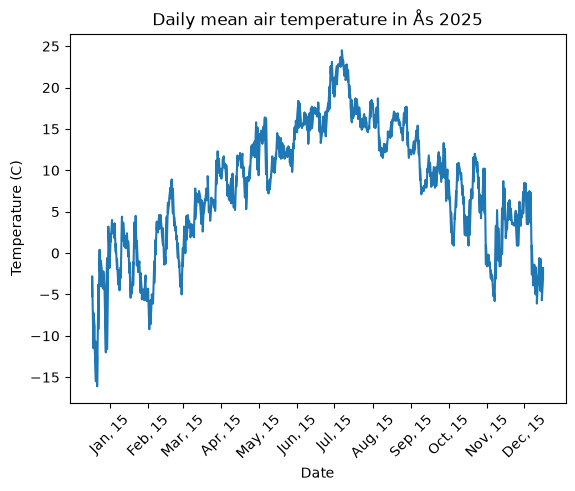

        ---Summary---
mean:            7.90
median:          8.35
min:           -16.10
max:            24.50


In [4]:
import datetime as dt

import matplotlib.pyplot as plt
import pandas as pd
import requests

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'mean(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31',
             }

client_id = open('/Users/norahattrem/Desktop/Programmering/Visual_Studio_Code/INF201/frost_credentials.txt').read().strip()

task1_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task1_response.status_code == 200

task1_json = task1_response.json()

task1_data = task1_json['data']

task1_list = []
task1_df = pd.DataFrame()
for i in range(len(task1_data)):
    row = pd.DataFrame(task1_data[i]['observations'])
    row['referenceTime'] = dt.datetime.strftime(dt.datetime.fromisoformat(task1_data[i]['referenceTime']), '%b, %d')
    row['sourceId'] = task1_data[i]['sourceId']
    task1_list.append(row)

task1_df = pd.concat(task1_list)
task1_df = task1_df.reset_index()

task1_summary = {'---Summary---': [f'{task1_df["value"].mean():.2f}', f'{task1_df["value"].median():.2f}',
                                   f'{task1_df["value"].min():.2f}', f'{task1_df["value"].max():.2f}']}
task1_summary_df = pd.DataFrame(task1_summary, index=['mean:', 'median:', 'min:', 'max:'])

date_list = [(dt.datetime.strptime(f'{i}, 15', '%m, %d').strftime('%b, %d')) for i in range(1, 13)]

plt.plot(task1_df['referenceTime'], task1_df['value'], label='2025')
plt.xticks(date_list, rotation=45)
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Daily mean air temperature in Ås 2025')
plt.show()

print(task1_summary_df)

Here we see the plot shows the mean temperatures for ås in 2025 as a line graph, with a summary of mean, median, minimum and maximum temperature for the entire year underneath. Here we see the expected results were we find lower temperatures at the start and end of the year, and the highest temperatures are in the middle of the year around june and july.

Resources: 
https://frost.met.no/python_example.html (for gettinng data from frost.met.no, used in all tasks)

https://www.w3schools.com/python/pandas/pandas_dataframes.asp (for how to create summary dataframe)

https://apxml.com/courses/intermediate-python-programming-ml/chapter-4-data-visualization-matplotlib-seaborn/matplotlib-customization (for how to customize the x-axis ticks)

Task 2: Precipitation

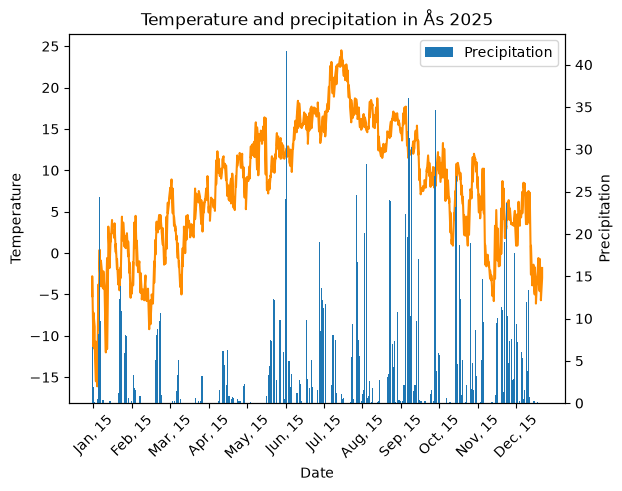

In [69]:
parameters = {'sources': 'SN17850',
              'elements': 'sum(precipitation_amount P1D)',
              'referencetime': '2025-01-01/2025-12-31',
            }

task2_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task2_response.status_code == 200

task2_json = task2_response.json()

task2_data = task2_json['data']

task2_list = []
task2_df = pd.DataFrame()
for i in range(len(task2_data)):
    row = pd.DataFrame(task2_data[i]['observations'])
    row['referenceTime'] = task2_data[i]['referenceTime']
    row['sourceId'] = task2_data[i]['sourceId']
    task2_list.append(row)

task2_df = pd.concat(task2_list)
task2_df = task2_df.reset_index()

fig, ax1 = plt.subplots()

ax1.plot(task2_df['referenceTime'], task1_df['value'], color='darkorange', label='Temperature')
ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature')
ax1.set_xticks(range(1, 365, 31), date_list, rotation=45)
ax2 = ax1.twinx()
ax2.bar(task2_df['referenceTime'], task2_df['value'], label='Precipitation')
ax2.set_ylabel('Precipitation')

plt.title('Temperature and precipitation in Ås 2025')
plt.legend()
plt.show()

Here the plot shows the meam temperature in ås 2025 in orange, same as the plot in task 1, in addition to the precipitation for 2025 in ås as a blue bar graph. Here we can see that the start of the year is generally drier and had less precipitation than the latter part of the year.

Resources:
https://pythonguides.com/matplotlib-two-y-axes-bar-plot/ (for how to have to y-axes in one plot)

https://matplotlib.org/stable/users/explain/axes/axes_ticks.html (for how to change the x-axis ticks)

Task 3: Historical temperature data

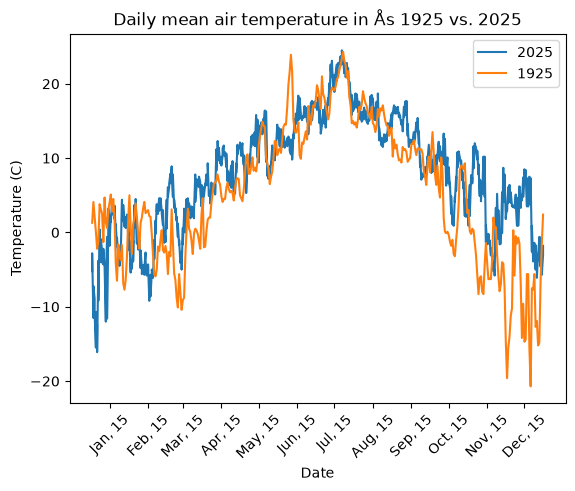

     ---Summary---     
           1925    2025
mean:      5.31    7.90
median:    5.30    8.35
min:     -20.70  -16.10
max:      24.30   24.50


In [ ]:
parameters = {'sources': 'SN17850',
              'elements': 'mean(air_temperature P1D)',
              'referencetime': '1925-01-01/1925-12-31',
             }

task3_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task3_response.status_code == 200

task3_json = task3_response.json()
task3_data = task3_json['data']

task3_list = []
task3_df = pd.DataFrame()
for i in range(len(task3_data)):
    row = pd.DataFrame(task3_data[i]['observations'])
    row['referenceTime'] = dt.datetime.strftime(dt.datetime.fromisoformat(task3_data[i]['referenceTime']),'%b, %d')
    row['sourceId'] = task3_data[i]['sourceId']
    task3_list.append(row)

task3_df = pd.concat(task3_list)
task3_df = task3_df.reset_index()

task3_summary = {'1925': [f'{task3_df["value"].mean():.2f}', f'{task3_df["value"].median():.2f}', 
                          f'{task3_df["value"].min():.2f}', f'{task3_df["value"].max():.2f}'],
     '2025': [f'{task1_df["value"].mean():.2f}', f'{task1_df["value"].median():.2f}', 
              f'{task1_df["value"].min():.2f}', f'{task1_df["value"].max():.2f}']}
task3_summary_df = pd.DataFrame(task3_summary, index=['mean:', 'median:', 'min:', 'max:'])

plt.plot(task1_df['referenceTime'], task1_df['value'], label='2025')
plt.plot(task3_df['referenceTime'], task3_df['value'], label='1925')
plt.xticks(date_list, rotation=45)
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Daily mean air temperature in Ås 1925 vs. 2025')
plt.legend()
plt.show()

print(f'     ---Summary---     \n{task3_summary_df}')


Here we see a blue line graph for the mean temperature in ås 2025, and an orange line graph for the mean temperature in ås 1925, and a summary of mean, median, minimum and maximum temperatures for both years. From both the plot and the summary we can see that in 1925 the temperatures were generally lower than those of 2025, which can be explained through climate change.

Task 4: Heatwaves

In [76]:
import yaml

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'max(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31',
             }

task4_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task4_response.status_code == 200

task4_json = task4_response.json()
task4_data = task4_json['data']

task4_list = []
task4_df = pd.DataFrame()
for i in range(len(task4_data)):
    row = pd.DataFrame(task4_data[i]['observations'])
    row['referenceTime'] = task4_data[i]['referenceTime']
    row['sourceId'] = task4_data[i]['sourceId']
    task4_list.append(row)

task4_df = pd.concat(task4_list)
task4_df = task4_df.reset_index()

def task_4(task4_df):
    temperature = task4_df["value"]
    year = task4_df["referenceTime"].iloc[0][:4]
    station_id = task4_df["sourceId"].iloc[0][:7]

    days = 0
    heatwaves = 0
    first_date = 0
    last_date = 0

    for i, temp in enumerate(temperature):
        if temp >= 27:
            days += 1

            if days == 1:
                start = task4_df["referenceTime"].iloc[i][:10]

            if days == 5:
                heatwaves += 1
                first_date = start

        else:
            if days >= 5:
                end = task4_df["referenceTime"].iloc[i-1][:10]
                last_date = end

            days = 0


        dates = [first_date, last_date]
        
        summary = {
        "dates": dates, 
        "station_id": station_id,
        "year": year,
    }

    with open("heatwaves.yml", "w", encoding="utf-8") as file:
        yaml.dump(summary, file, sort_keys=False)

    return summary

result = task_4(task4_df)
print(result) 

{'dates': ['2025-07-16', '2025-07-20'], 'station_id': 'SN17850', 'year': '2025'}


Here we see a list of dates in which a heatwave was happening between, as in the temperature was over 27 degrees for at least five days, as well as the station id for the area and the year. This information can also be found summarised in the heatwaves.yml file. The one heatwave found for the year was in the middle of july, which makes sense when comparing to earlier graphs as that is where you would find the highest temperatures.

Task 5: Moving average temperature

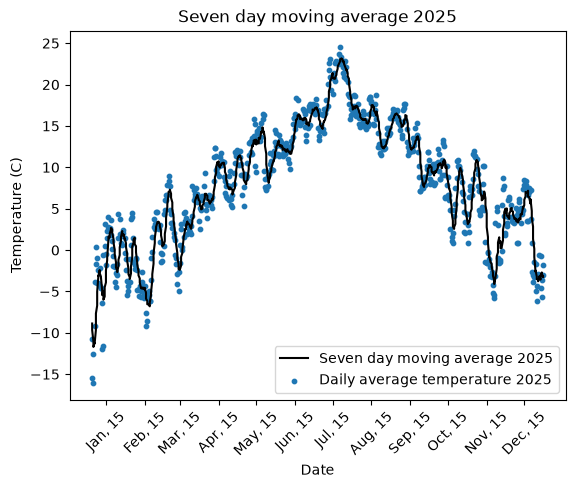

In [ ]:
import numpy as np


def seven_day_moving_average(temperatures: pd.DataFrame) -> np.ndarray:
    """
    Calculates the 7 day moving average for a set of temperatures and returns
    a numpy array with those values for the set timeframe
    """
    moving_average = np.array([])
    start = 0
    end = 7
    for _ in range(len(temperatures)):
        if end <= len(temperatures):
            total = 0
            for i in range(start, end):
                total += temperatures['value'][i]
            moving_average = np.append(moving_average, total / 7)
            start += 1
            end += 1
    return moving_average


task5 = seven_day_moving_average(task1_df)

plt.plot(task1_df['referenceTime'][6:], task5, 'k', label='Seven day moving average 2025')
plt.scatter(task1_df['referenceTime'][6:], task1_df['value'][6:], label='Daily average temperature 2025', s=10)
plt.xticks(date_list, rotation=45)
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Seven day moving average 2025')
plt.legend()
plt.show()

Here we have the 7 day moving average of the mean temperature in ås 2025 as a black line graph, and the mean temperature for ås in 2025 as blue points. Here we see that the 7 day moving average generally line up with the temperature points, but is a slightly smoother graph.

Resource: https://www.w3schools.com/python/matplotlib_markers.asp (for how to customize look of plot)


Github repository: https://github.com/GoodDag/Deliverable_1/tree/main